# 16 · Validación transversal, sensibilidad e interpretaciones provisionales

**Objetivo:** evaluar cuánto dependen los hallazgos de la unidad, los controles y las decisiones operativas. No se buscan p-valores favorables. Las interpretaciones son borradores generados con resultados; el README y la escritura final quedan para el cierre.

**Contrato inferencial:** H1/H2a/H2b/H4 se evalúan a nivel barrio/comuna; H3, a nivel aviso con errores agrupados por barrio. Pruebas bilaterales, α=0,05 y familias BH declaradas. Los IC de 95% son puntuales, no simultáneos. Datos observacionales de oferta capturada, no muestra probabilística ni transacciones. Autocorrelación, captura por portal, geocodificación y desfase censal limitan generalización.

Se usan insumos de 07–15. Exporta tablas y figuras con sufijo `v2` en `data/processed/reports/robustez_pe3/` y una matriz de evidencia. La evaluación completa debe conservar resultados negativos y casos no estimables.

Esta auditoría es exploratoria retrospectiva: fijar familias transparenta esta revisión, no constituye un preregistro.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown
from src import config, geo, eda, robustez as R
from src.robustez_precios import model_audit
OUT=config.REPORTS_DIR/'robustez_pe3';OUT.mkdir(exist_ok=True,parents=True)
base=pd.read_csv(config.PROCESSED_DIR/'df_publicaciones_enriquecidas_v1.csv',low_memory=False,dtype={'id_publicacion':str})
kb=pd.read_csv(config.PROCESSED_DIR/'kpis_barrio_v1.csv').set_index('barrio_oficial')
kc=pd.read_csv(config.PROCESSED_DIR/'kpis_comuna_v1.csv').set_index('comuna')
ctx=pd.read_csv(config.PROCESSED_DIR/'features_contextuales_barrio_v1.csv')
assert kb.index.is_unique and kc.index.is_unique
assert not base.duplicated(['fuente_norm','id_publicacion','tipo_operacion_norm']).any()
eda.estilo()
def save(table,name):
    table.to_csv(OUT/(name+'_v2.csv'),index=False)
    return table
def figure(name):
    plt.tight_layout();plt.savefig(OUT/(name+'_v2.png'),dpi=130,bbox_inches='tight');plt.show()
def note(text):display(Markdown('**Borrador de interpretación.** '+text))
print('Universo:',len(base),'publicaciones;',len(kb),'barrios;',len(kc),'comunas.')

Universo: 67887 publicaciones; 48 barrios; 15 comunas.


## 1. H1, H2a, H2b y H4: magnitud, incertidumbre y unidad correcta

Familia primaria fijada: H1 cultura/gastronomía vs Airbnb relativo en barrios; H2a tamaño medio vs porcentaje 1–2 ambientes por operación en comunas; H2b cultura/educación/verde vs alquileres por 1.000 viviendas; H4 Airbnb vs precio y disponibilidad de alquiler permanente. H0: rho=0; H1 estadística: rho≠0. Se reporta además si la dirección coincide con la hipótesis sustantiva. No rechazar no equivale a demostrar efecto cero.

Cada contraste incorpora Spearman, IC bootstrap pareado (999), permutación bilateral (1.999), BH sobre la familia completa y rango leave-one-out. Sensibilidad parcial de rangos controla centralidad geográfica mediante distancia del centroide territorial al Obelisco y área. Es un control aproximado, no una solución causal; otra familia BH. Permutaciones requieren intercambiabilidad y los diagnósticos espaciales pueden cuestionarla.

,contraste,n,rho,lo,hi,p_perm,q_BH,p_Holm,loo_min,loo_max,direccion_compatible
0,H1_cultura,48,0.8548,0.7133,0.9197,0.0005,0.0017,0.0050,0.8455,0.8824,True
1,H1_gastronomia,48,0.6464,0.3888,0.8123,0.0005,0.0017,0.0050,0.6239,0.6794,True
2,H2a_venta,15,-0.2857,-0.7190,0.3622,0.3095,0.3869,0.9285,-0.4462,-0.1209,True
3,H2a_alquiler,15,0.0286,-0.6107,0.7327,0.9295,0.9295,1.0000,-0.1341,0.2659,False
4,H2a_alquiler_temporal,15,-0.5000,-0.8629,0.0783,0.0695,0.1158,0.3475,-0.6000,-0.3846,True
5,H2b_culturales,15,0.6857,0.1875,0.9230,0.0080,0.0160,0.0480,0.6132,0.7934,True
6,H2b_educacion,15,0.1107,-0.5820,0.7071,0.6930,0.7700,1.0000,-0.0945,0.3055,True
7,H2b_espacios_verdes,15,0.4107,-0.2669,0.7719,0.1300,0.1857,0.5200,0.2879,0.5121,True
8,H4_precio,15,0.9071,0.6217,0.9854,0.0005,0.0017,0.0050,0.8857,0.9385,True
9,H4_disponibilidad,15,0.8321,0.5072,0.9706,0.0010,0.0025,0.0070,0.7934,0.8857,False


,contraste,n,rho,lo,hi,p_perm,loo_min,loo_max,fraccion_boot_signo,q_BH
0,H1_cultura,48,0.6313,0.3726,0.7886,0.0005,0.5842,0.6926,0.9990,0.0050
1,H1_gastronomia,48,0.3545,0.0596,0.6171,0.0170,0.2863,0.4223,0.9860,0.0340
2,H2a_venta,15,-0.3614,-0.8578,0.2802,0.2325,-0.4745,-0.1448,0.8839,0.3321
3,H2a_alquiler,15,0.2139,-0.5780,0.7525,0.4775,0.0344,0.3662,0.6937,0.5306
4,H2a_alquiler_temporal,15,-0.2956,-0.7831,0.2823,0.3280,-0.4376,-0.1678,0.8659,0.4100
5,H2b_culturales,15,0.8003,0.1153,0.9346,0.0035,0.6298,0.8634,0.9849,0.0087
6,H2b_educacion,15,-0.0945,-0.8445,0.7205,0.7500,-0.4833,0.1422,0.5721,0.7500
7,H2b_espacios_verdes,15,0.4296,-0.1372,0.8520,0.1390,0.2885,0.5257,0.9379,0.2317
8,H4_precio,15,0.9081,0.6506,0.9854,0.0010,0.8706,0.9422,1.0000,0.0050
9,H4_disponibilidad,15,0.8275,0.4273,0.9678,0.0015,0.7766,0.9002,0.9990,0.0050


**Borrador de interpretación.** **H1_cultura**: n=48, rho=+0.85, IC95% [+0.71, +0.92], q=0.002; asociación detectada en esta familia. Dirección compatible con la expectativa. Al quitar una unidad: [+0.85, +0.88].

**Borrador de interpretación.** **H1_gastronomia**: n=48, rho=+0.65, IC95% [+0.39, +0.81], q=0.002; asociación detectada en esta familia. Dirección compatible con la expectativa. Al quitar una unidad: [+0.62, +0.68].

**Borrador de interpretación.** **H2a_venta**: n=15, rho=-0.29, IC95% [-0.72, +0.36], q=0.387; incertidumbre insuficiente para rechazar H0 en esta familia. Dirección compatible con la expectativa. Al quitar una unidad: [-0.45, -0.12].

...

**Borrador de interpretación.** **H2b_culturales**: n=15, rho=+0.69, IC95% [+0.19, +0.92], q=0.016; asociación detectada en esta familia. Dirección compatible con la expectativa. Al quitar una unidad: [+0.61, +0.79].

**Borrador de interpretación.** **H2b_educacion**: n=15, rho=+0.11, IC95% [-0.58, +0.71], q=0.770; incertidumbre insuficiente para rechazar H0 en esta familia. Dirección compatible con la expectativa. Al quitar una unidad: [-0.09, +0.31].

**Borrador de interpretación.** **H2b_espacios_verdes**: n=15, rho=+0.41, IC95% [-0.27, +0.77], q=0.186; incertidumbre insuficiente para rechazar H0 en esta familia. Dirección compatible con la expectativa. Al quitar una unidad: [+0.29, +0.51].

**Borrador de interpretación.** **H4_precio**: n=15, rho=+0.91, IC95% [+0.62, +0.99], q=0.002; asociación detectada en esta familia. Dirección compatible con la expectativa. Al quitar una unidad: [+0.89, +0.94].

**Borrador de interpretación.** **H4_disponibilidad**: n=15, rho=+0.83, IC95% [+0.51, +0.97], q=0.003; asociación detectada en esta familia. Dirección contraria con la expectativa. Al quitar una unidad: [+0.79, +0.89].

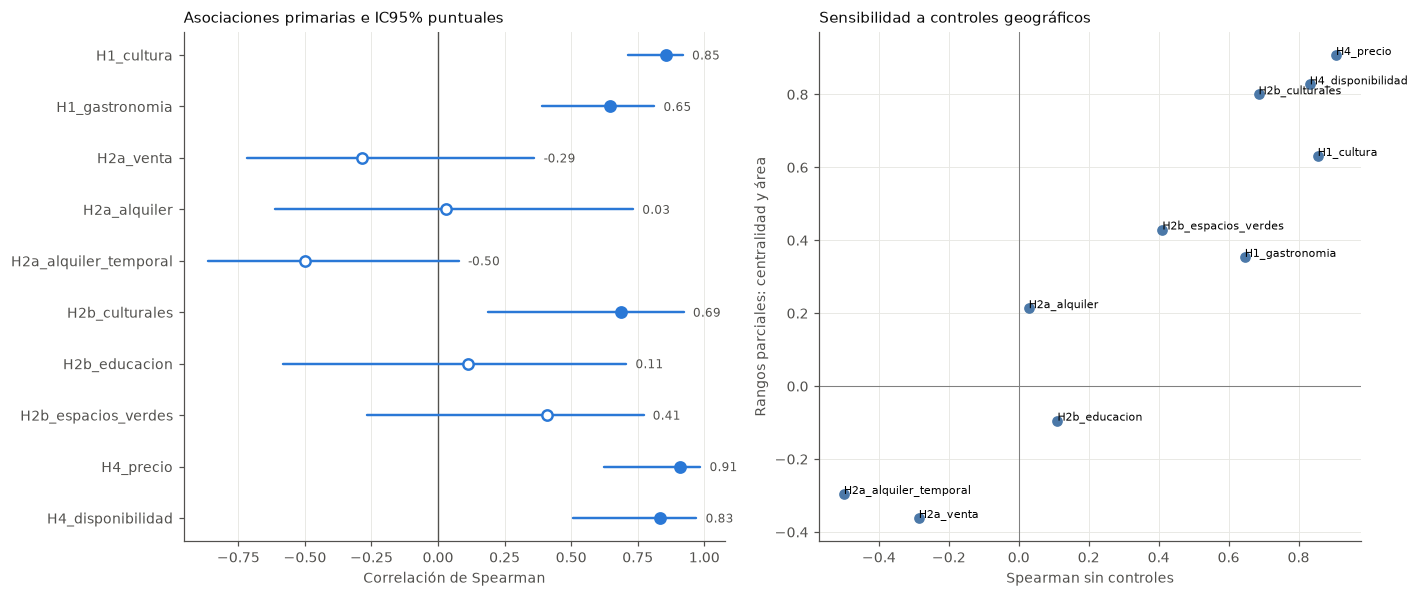

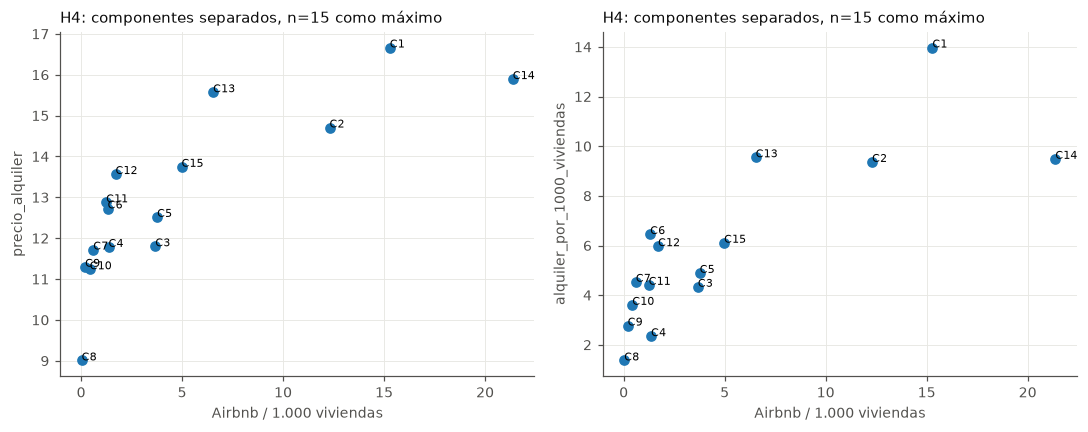

In [2]:
# Centroide planar aproximado de polígonos oficiales, ponderando áreas de anillos.
barrios=geo.cargar_barrios(config.EXTERNAS_RAW_DIR/'barrios.geojson')
def polygon_centroid(paths):
    vals=[]
    for path in paths:
        xy=path.vertices[:,:2];xx=xy[:,0];yy=xy[:,1]
        cross=xx*np.roll(yy,-1)-np.roll(xx,-1)*yy
        area=cross.sum()/2
        if abs(area)>1e-12:
            vals.append((abs(area),np.array([((xx+np.roll(xx,-1))*cross).sum(),((yy+np.roll(yy,-1))*cross).sum()])/(6*area)))
    return np.average(np.array([v[1] for v in vals]),axis=0,weights=[v[0] for v in vals])
cent=pd.DataFrame([polygon_centroid(p) for p in barrios['_paths']],columns=['lon_centro','lat_centro'])
cent.index=barrios.barrio_oficial
kb=kb.join(cent)
# Distancia equirectangular local; adecuada como proxy de centralidad dentro de CABA.
kb['centro_km']=np.hypot((kb.lon_centro+58.3816)*111*np.cos(np.radians(-34.6)),(kb.lat_centro+34.6037)*111)
kb['airbnb_relativo']=kb.n_airbnb/kb.n_alquiler.replace(0,np.nan)
agg=ctx.groupby('comuna').sum(numeric_only=True)
comm=kc.copy()
for col in ['culturales','educacion','espacios_verdes']:
    comm['dens_'+col]=agg['n_'+col]/agg.area_km2
geo_com=kb.assign(comuna=pd.to_numeric(kb.comuna)).groupby('comuna')
com_cent=geo_com.apply(lambda d:pd.Series(np.average(d[['lon_centro','lat_centro']],axis=0,weights=d.area_km2),index=['lon','lat']),include_groups=False)
comm['centro_km']=np.hypot((com_cent.lon+58.3816)*111*np.cos(np.radians(-34.6)),(com_cent.lat+34.6037)*111)
comm['area_control']=kc.superficie_km2
rent=base[base.tipo_operacion_norm.eq('alquiler') & base.precio_m2_usd.gt(0) & ~base.precio_m2_usd_fuera_rango_flag]
comm['precio_alquiler']=rent.groupby('comuna_oficial').precio_m2_usd.median()
comm['n_precio']=rent.groupby('comuna_oficial').size()
comm.loc[comm.n_precio.lt(30),'precio_alquiler']=np.nan
specs=[('H1_cultura','H1',kb,'densidad_culturales_km2','airbnb_relativo',1,'barrio'),
       ('H1_gastronomia','H1',kb,'densidad_gastronomia_km2','airbnb_relativo',1,'barrio')]
depart=base[base.tipo_propiedad.eq('departamento') & base.ambientes_ref.between(1,15)]
for op in ['venta','alquiler','alquiler_temporal']:
    part=depart[depart.tipo_operacion_norm.eq(op)].assign(chica=lambda d:d.ambientes_ref.le(2))
    tab=part.groupby('comuna_oficial').chica.agg(pct='mean',n='size').join(comm[['tamano_medio_hogar','centro_km','area_control']])
    tab.loc[tab.n.lt(30),'pct']=np.nan
    specs.append(('H2a_'+op,'H2a',tab,'tamano_medio_hogar','pct',-1,'comuna'))
for service in ['culturales','educacion','espacios_verdes']:
    specs.append(('H2b_'+service,'H2b',comm,'dens_'+service,'alquiler_por_1000_viviendas',1,'comuna'))
specs.extend([('H4_precio','H4',comm,'airbnb_por_1000_viviendas','precio_alquiler',1,'comuna'),
              ('H4_disponibilidad','H4',comm,'airbnb_por_1000_viviendas','alquiler_por_1000_viviendas',-1,'comuna')])
rows=[];partial=[]
for name,h,t,x,y,direction,unit in specs:
    result=R.association(t[x],t[y])
    rows.append(dict(contraste=name,hipotesis=h,unidad=unit,esperado=direction,**result))
    controls=t[['centro_km','area_km2' if unit=='barrio' else 'area_control']]
    result=R.association(t[x],t[y],controls=controls)
    partial.append(dict(contraste=name,**result))
evidence=pd.DataFrame(rows);evidence['q_BH']=R.bh(evidence.p_perm)
from statsmodels.stats.multitest import multipletests
evidence['p_Holm']=np.nan
valid=evidence.p_perm.notna()
evidence.loc[valid,'p_Holm']=multipletests(evidence.loc[valid,'p_perm'],method='holm')[1]
evidence['direccion_compatible']=np.sign(evidence.rho).eq(evidence.esperado)
evidence['H0']='rho=0';evidence['H1_estadistica']='rho distinto de cero; bilateral'
part=pd.DataFrame(partial);part['q_BH']=R.bh(part.p_perm)
save(evidence,'hipotesis_primarias');save(part,'rangos_parciales_centralidad')
display(evidence[['contraste','n','rho','lo','hi','p_perm','q_BH','p_Holm','loo_min','loo_max','direccion_compatible']].round(4));display(part.round(4))
for _,r in evidence.iterrows():
    verdict='asociación detectada en esta familia' if r.q_BH<.05 else 'incertidumbre insuficiente para rechazar H0 en esta familia'
    note(f"**{r.contraste}**: n={r.n}, rho={r.rho:+.2f}, IC95% [{r.lo:+.2f}, {r.hi:+.2f}], q={r.q_BH:.3f}; {verdict}. "
         f"Dirección {'compatible' if r.direccion_compatible else 'contraria'} con la expectativa. "
         f"Al quitar una unidad: [{r.loo_min:+.2f}, {r.loo_max:+.2f}].")
fig,axes=plt.subplots(1,2,figsize=(13,5.5))
eda.forest(axes[0],evidence,col_etiqueta='contraste');axes[0].set_title('Asociaciones primarias e IC95% puntuales')
axes[1].scatter(evidence.rho,part.rho,color='#4b78a8')
for a,b,label in zip(evidence.rho,part.rho,evidence.contraste):axes[1].annotate(label,(a,b),fontsize=7)
axes[1].axhline(0,color='gray',lw=.7);axes[1].axvline(0,color='gray',lw=.7)
axes[1].set(xlabel='Spearman sin controles',ylabel='Rangos parciales: centralidad y área',title='Sensibilidad a controles geográficos')
figure('hipotesis_forest_controles')
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,y in zip(axes,['precio_alquiler','alquiler_por_1000_viviendas']):
    ax.scatter(comm.airbnb_por_1000_viviendas,comm[y])
    for idx,r in comm.iterrows():ax.annotate(f'C{int(idx)}',(r.airbnb_por_1000_viviendas,r[y]),fontsize=7)
    ax.set(xlabel='Airbnb / 1.000 viviendas',ylabel=y,title='H4: componentes separados, n=15 como máximo')
figure('h4_componentes')

## 2. Dependencia espacial y contraste de distribuciones por geografía externa

Moran I con 3 y 5 vecinos de centroides: H0 de aleatorización espacial, bilateral (1.999 permutaciones, BH conjunto). La persistencia espacial obliga a leer p de correlaciones como exploratorios; no basta con multiplicar el número de avisos.

Contraste complementario con división **administrativa externa**: barrios de comunas 1–3 frente al resto, fijada como aproximación de zona central. No son clusters aprendidos. Mann–Whitney contrasta orden/distribuciones (no exclusivamente medianas), KS distribución completa y Brown–Forsythe dispersión. Se acompaña Cliff e IC de diferencia de medianas. Cada tipo de test tiene su propia familia BH. No se presume causalidad de pertenecer a esa zona.

,variable,vecinos,n,I,esperado,p_perm,q_BH
0,airbnb_por_km2,3,48,0.6447,-0.0213,0.0005,0.0009
1,airbnb_por_km2,5,48,0.5603,-0.0213,0.0005,0.0009
2,densidad_culturales_km2,3,48,0.4958,-0.0213,0.0005,0.0009
3,densidad_culturales_km2,5,48,0.4350,-0.0213,0.0005,0.0009
4,mediana_precio_m2_alquiler_usd,3,41,0.1780,-0.0250,0.0140,0.0140
5,mediana_precio_m2_alquiler_usd,5,41,0.1859,-0.0250,0.0010,0.0012
6,residuo_H1_cultura_con_controles,3,48,0.3498,-0.0213,0.0010,0.0012


,variable,n_a,n_b,diferencia_mediana,lo,hi,cliff,p_mw,p_ks,p_brown_forsythe,q_mw,q_ks,q_brown_forsythe
0,airbnb_por_km2,9,39,98.7235,38.2438,201.2516,0.8405,0.0001,0.0000,0.0006,0.0003,0.0001,0.0017
1,mediana_precio_m2_venta_usd,9,39,-240.9518,-618.4211,326.3281,-0.1624,0.4595,0.4164,0.3494,0.5391,0.4164,0.3494
2,mediana_precio_m2_alquiler_usd,9,32,0.1545,-1.3351,3.5621,0.1389,0.5391,0.3854,0.0540,0.5391,0.4164,0.0809


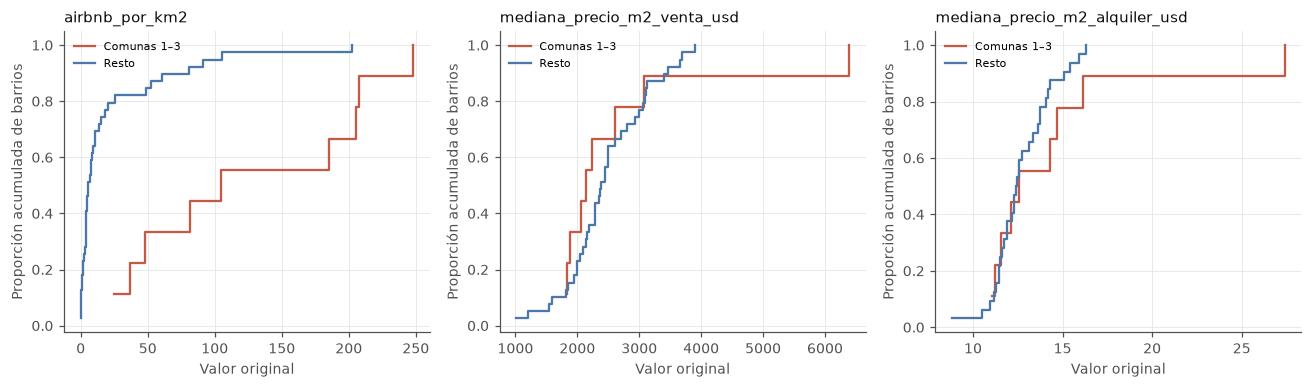

**Borrador de interpretación.** Moran detecta dependencia (q<0,05) en 7 de 7 combinaciones. La geografía administrativa y los patrones espaciales condicionan las asociaciones: los p no son garantía de representatividad.

,operacion,ambientes_max,n_minimo,comunas,avisos,rho
0,venta,1,20,15,42313,-0.525
1,venta,1,30,15,42313,-0.525
2,venta,1,50,15,42313,-0.525
3,venta,2,20,15,42313,-0.286
4,venta,2,30,15,42313,-0.286
5,venta,2,50,15,42313,-0.286
6,alquiler,1,20,15,9652,-0.168
7,alquiler,1,30,15,9652,-0.168
8,alquiler,1,50,15,9652,-0.168
9,alquiler,2,20,15,9652,0.029


**Borrador de interpretación.** H2a se vuelve a calcular con 1 y 2 ambientes y tres mínimos de avisos. Cambios de signo/cobertura señalan dependencia de la definición; no se elige la alternativa con menor p.

In [3]:
spatial=[]
coords=kb[['lon_centro','lat_centro']].to_numpy()*[np.cos(np.radians(-34.6)),1]
for variable in ['airbnb_por_km2','densidad_culturales_km2','mediana_precio_m2_alquiler_usd']:
    for neighbors in [3,5]:
        spatial.append(dict(variable=variable,vecinos=neighbors,**R.moran(kb[variable],coords,k=neighbors)))
# Diagnóstico residual de H1 con controles, además del patrón espacial marginal.
rt=kb[['airbnb_relativo','densidad_culturales_km2','centro_km','area_km2']].dropna()
ranked=rt.rank().to_numpy()
design=np.column_stack([np.ones(len(rt)),ranked[:,1:]])
resid=ranked[:,0]-design@np.linalg.lstsq(design,ranked[:,0],rcond=None)[0]
spatial.append(dict(variable='residuo_H1_cultura_con_controles',vecinos=3,
    **R.moran(resid,coords[kb.index.get_indexer(rt.index)])))
spatial=pd.DataFrame(spatial);spatial['q_BH']=R.bh(spatial.p_perm)
save(spatial,'autocorrelacion_espacial');display(spatial.round(4))
groups=[];central=kb.comuna.isin([1,2,3])
variables=['airbnb_por_km2','mediana_precio_m2_venta_usd','mediana_precio_m2_alquiler_usd']
for variable in variables:
    groups.append(dict(variable=variable,**R.two_groups(kb.loc[central,variable],kb.loc[~central,variable])))
groups=pd.DataFrame(groups)
for test in ['mw','ks','brown_forsythe']:groups['q_'+test]=R.bh(groups['p_'+test])
save(groups,'distribuciones_geografia_externa');display(groups.round(4))
fig,axes=plt.subplots(1,3,figsize=(12,3.6))
for ax,v in zip(axes,variables):
    for mask,label,color in [(central,'Comunas 1–3','#c45a46'),(~central,'Resto','#4b78a8')]:
        vals=np.sort(kb.loc[mask,v].dropna());ax.step(vals,np.arange(1,len(vals)+1)/len(vals),where='post',label=label,color=color)
    ax.set(title=v,xlabel='Valor original',ylabel='Proporción acumulada de barrios');ax.legend(fontsize=7)
figure('ecdf_geografia_externa')
note(f"Moran detecta dependencia (q<0,05) en {int((spatial.q_BH<.05).sum())} de {len(spatial)} combinaciones. "
     'La geografía administrativa y los patrones espaciales condicionan las asociaciones: los p no son garantía de representatividad.')
# Sensibilidad H2a a definición de unidad pequeña y soporte, sin buscar cortes significativos.
h2a_sensitivity=[]
for op in ['venta','alquiler','alquiler_temporal']:
    for max_rooms in [1,2]:
        small=depart[depart.tipo_operacion_norm.eq(op)].assign(small=lambda d:d.ambientes_ref.le(max_rooms))
        t=small.groupby('comuna_oficial').small.agg(proporcion='mean',n='size').join(kc[['tamano_medio_hogar']])
        for minimum in [20,30,50]:
            usable=t[t.n.ge(minimum)].dropna()
            rho=stats.spearmanr(usable.tamano_medio_hogar,usable.proporcion).statistic if len(usable)>=5 else np.nan
            h2a_sensitivity.append(dict(operacion=op,ambientes_max=max_rooms,n_minimo=minimum,comunas=len(usable),avisos=int(usable.n.sum()),rho=rho))
h2a_sensitivity=pd.DataFrame(h2a_sensitivity);save(h2a_sensitivity,'h2a_definicion_soporte');display(h2a_sensitivity.round(3))
note('H2a se vuelve a calcular con 1 y 2 ambientes y tres mínimos de avisos. Cambios de signo/cobertura señalan dependencia de la definición; no se elige la alternativa con menor p.')


## 3. Prioridades comunales: sensibilidad operativa y cambiaria

Se conserva la regla de tres señales de 09. Grilla declarada: cortes altos P60/P70/P75/P80/P90 y complementarios bajos; mínimo de 20/30/50/100 precios válidos. No se elige la grilla que produzca más candidatas. Comparación nominal de MEP −10%, base y +10%, aplicada solo a avisos ARS antes de recalcular medianas; no es pronóstico, inflación ni intervalo de confianza. Se mantiene fijo el conjunto de avisos y se explicita que cambia solo la conversión. Reportar ceros y cambios de elegibilidad.

,comuna,escenarios_evaluables,fraccion_candidata,senales_medias
0,1,60,0.0,2.00
1,2,60,0.0,1.40
2,3,60,0.0,0.45
3,4,60,0.0,1.00
4,5,60,0.0,0.20
5,6,60,0.0,0.00
6,7,60,0.0,0.05
7,8,45,0.0,1.00
8,9,60,0.0,0.85
9,10,60,0.0,0.65


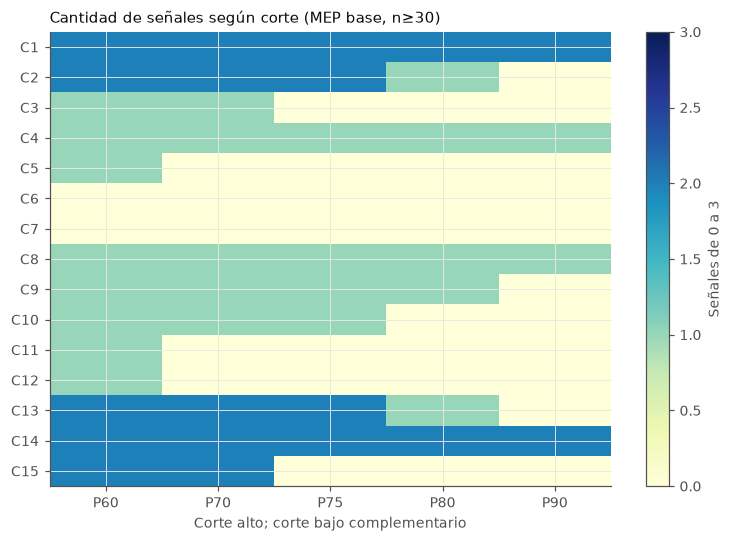

**Borrador de interpretación.** En la grilla hay 885 combinaciones comuna–escenario evaluables; 0 reúnen las tres señales. La fracción de escenarios no es una probabilidad de déficit. Las comunas con señales parciales siguen requiriendo lectura por dimensión; no forzar un ranking cuando la regla no discrimina.

In [4]:
prior=[]
for shock in [-.1,0,.1]:
    rr=rent.copy();rr['precio_escenario']=rr.precio_m2_usd/np.where(rr.moneda_norm.eq('ARS'),1+shock,1)
    med=rr.groupby('comuna_oficial').precio_escenario.agg(precio='median',n='size')
    for minimum in [20,30,50,100]:
        t=comm.join(med[['precio','n']]);t=t[t.n.ge(minimum)].dropna(subset=['precio','airbnb_por_1000_viviendas','alquiler_por_1000_viviendas'])
        if len(t)<5:continue
        for q in [.6,.7,.75,.8,.9]:
            flags=pd.DataFrame({'temporario_alto':t.airbnb_por_1000_viviendas.ge(t.airbnb_por_1000_viviendas.quantile(q)),
                'permanente_bajo':t.alquiler_por_1000_viviendas.le(t.alquiler_por_1000_viviendas.quantile(1-q)),
                'precio_alto':t.precio.ge(t.precio.quantile(q))})
            for comuna,row in flags.iterrows():
                prior.append(dict(comuna=comuna,MEP_shock=shock,n_minimo=minimum,cuantil=q,n_evaluables=len(t),
                                  senales=int(row.sum()),candidata=bool(row.all())))
prior=pd.DataFrame(prior);save(prior,'sensibilidad_priorizacion')
frequency=prior.groupby('comuna').agg(escenarios_evaluables=('candidata','size'),fraccion_candidata=('candidata','mean'),senales_medias=('senales','mean')).reset_index()
save(frequency,'estabilidad_priorizacion');display(frequency.round(3))
heat=prior.query('MEP_shock == 0 and n_minimo == 30').pivot(index='comuna',columns='cuantil',values='senales')
fig,ax=plt.subplots(figsize=(7,5));im=ax.imshow(heat,aspect='auto',vmin=0,vmax=3,cmap='YlGnBu')
ax.set_yticks(range(len(heat)),[f'C{int(i)}' for i in heat.index]);ax.set_xticks(range(len(heat.columns)),[f'P{int(x*100)}' for x in heat.columns])
ax.set(title='Cantidad de señales según corte (MEP base, n≥30)',xlabel='Corte alto; corte bajo complementario')
fig.colorbar(im,ax=ax,label='Señales de 0 a 3');figure('sensibilidad_cortes')
note(f"En la grilla hay {len(prior)} combinaciones comuna–escenario evaluables; "
     f"{int(prior.candidata.sum())} reúnen las tres señales. La fracción de escenarios no es una probabilidad de déficit. "
     'Las comunas con señales parciales siguen requiriendo lectura por dimensión; no forzar un ranking cuando la regla no discrimina.')

## 4. PCA y factores: incertidumbre de los ejes y del subespacio

Bootstrap de 299 muestras de barrios, reajustando escala. Alineación por asignación y signo evita confundir cambios convencionales con inestabilidad. Se reportan pesos, intervalos y ángulo máximo entre subespacios PC1–PC3. Los pesos `components_` son vectores propios normalizados; no se presentan como correlaciones variable–componente. Bootstrap de barrios no preserva estructura espacial: evidencia exploratoria, no certificación de un índice.

El factor unidimensional usa la escala original estandarizada de 14, sin introducir precios ni anuncios. Se alinea su signo y se examinan pesos bootstrap; si falla adecuación o estabilidad, se conserva solo como resumen exploratorio.

,componente,variable,peso,lo,hi,signo_estable
0,PC1,densidad_subte_km2,0.449,0.310,0.505,1.000
1,PC1,densidad_tren_km2,-0.046,-0.210,0.207,0.622
2,PC1,densidad_metrobus_km2,0.283,-0.141,0.411,0.936
3,PC1,densidad_hospitales_km2,-0.003,-0.167,0.246,0.458
4,PC1,densidad_educacion_km2,0.315,0.189,0.459,1.000
5,PC1,densidad_culturales_km2,0.526,0.475,0.544,1.000
6,PC1,densidad_gastronomia_km2,0.511,0.420,0.538,1.000
7,PC1,densidad_espacios_verdes_km2,0.245,-0.063,0.372,0.943
8,PC1,pct_superficie_verde,-0.143,-0.309,0.170,0.823
9,PC2,densidad_subte_km2,-0.029,-0.352,0.166,0.645


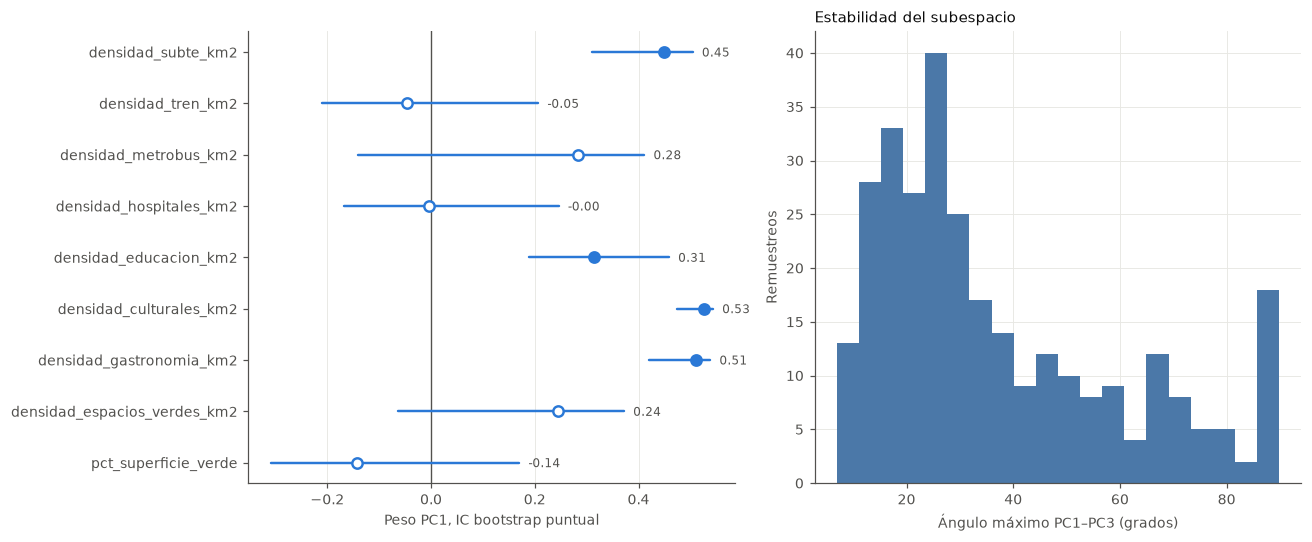

,variable,peso,lo,hi
0,densidad_subte_km2,0.763,0.212,0.929
1,densidad_tren_km2,-0.156,-0.296,0.032
2,densidad_metrobus_km2,0.809,-0.071,0.913
3,densidad_hospitales_km2,-0.106,-0.221,0.137
4,densidad_educacion_km2,0.345,0.161,0.642
5,densidad_culturales_km2,0.997,0.930,0.999
6,densidad_gastronomia_km2,0.939,0.886,0.995
7,densidad_espacios_verdes_km2,0.424,0.229,0.638
8,pct_superficie_verde,-0.085,-0.192,0.065


**Borrador de interpretación.** El ángulo mediano del subespacio PCA es 29.7° y P95=86.1°. Pesos con intervalos que cruzan cero admiten lecturas inestables. Comparar estabilidad de ejes y del subespacio antes de nombrarlos; los factores permanecen como perfiles urbanos, no medidas de necesidad habitacional.

In [5]:
urban=[c for c in kb.columns if c.startswith('densidad_')]+['pct_superficie_verde']
urban_frame=kb[urban].dropna()
load_ci,variance_boot,angles=R.pca_bootstrap(urban_frame)
save(load_ci,'pca_pesos_bootstrap');save(variance_boot,'pca_varianza_bootstrap')
save(pd.DataFrame({'angulo_maximo_grados':angles}),'pca_subespacio_bootstrap')
display(load_ci.round(3))
fig,axes=plt.subplots(1,2,figsize=(12,5))
first=load_ci[load_ci.componente.eq('PC1')].copy();first['label']=first.variable
eda.forest(axes[0],first,col_etiqueta='label',col_valor='peso',xlabel='Peso PC1, IC bootstrap puntual')
axes[1].hist(angles,bins=20,color='#4b78a8');axes[1].set(xlabel='Ángulo máximo PC1–PC3 (grados)',ylabel='Remuestreos',title='Estabilidad del subespacio')
figure('pca_estabilidad')
raw=urban_frame.to_numpy();xz=StandardScaler().fit_transform(raw)
corr=np.corrcoef(xz,rowvar=False);inv=np.linalg.pinv(corr)
partial_corr=-inv/np.sqrt(np.outer(np.diag(inv),np.diag(inv)));np.fill_diagonal(partial_corr,0)
off=corr.copy();np.fill_diagonal(off,0)
kmo_audit=(off**2).sum()/((off**2).sum()+(partial_corr**2).sum())
bart_audit=-(len(xz)-1-(2*xz.shape[1]+5)/6)*np.log(max(np.linalg.det(corr),1e-12))
bart_p=stats.chi2.sf(bart_audit,xz.shape[1]*(xz.shape[1]-1)/2)
rng=np.random.default_rng(2026)
null_eig=np.array([np.linalg.eigvalsh(np.corrcoef(rng.normal(size=xz.shape),rowvar=False))[::-1] for _ in range(299)])
obs_eig=np.linalg.eigvalsh(corr)[::-1]
factor_count=int((obs_eig>np.quantile(null_eig,.95,axis=0)).sum())
adequate=len(xz)>=5*xz.shape[1] and kmo_audit>=.6 and bart_p<.05 and factor_count==1
save(pd.DataFrame([dict(n=len(xz),p=xz.shape[1],KMO=kmo_audit,p_Bartlett=bart_p,factores_parallel=factor_count,bootstrap_unifactorial_elegible=adequate)]),'factor_adecuacion')
if adequate:
    ref_factor=FactorAnalysis(n_components=1,random_state=2026).fit(xz).components_[0]
    factor_weights=[]
    for _ in range(199):
        ix=rng.integers(0,len(raw),len(raw));xx=StandardScaler().fit_transform(raw[ix])
        f=FactorAnalysis(n_components=1,random_state=2026,max_iter=1000).fit(xx).components_[0]
        factor_weights.append(f*(1 if f@ref_factor>=0 else -1))
    factor_weights=np.asarray(factor_weights)
    factor_ci=pd.DataFrame({'variable':urban,'peso':ref_factor,'lo':np.quantile(factor_weights,.025,axis=0),'hi':np.quantile(factor_weights,.975,axis=0)})
    save(factor_ci,'factor_unidimensional_bootstrap');display(factor_ci.round(3))
else:
    note('No se fuerza bootstrap unifactorial: revisar adecuación o número de factores de parallel analysis.')
note(f"El ángulo mediano del subespacio PCA es {np.median(angles):.1f}° y P95={np.quantile(angles,.95):.1f}°. "
     'Pesos con intervalos que cruzan cero admiten lecturas inestables. Comparar estabilidad de ejes y del subespacio antes de nombrarlos; '
     'los factores permanecen como perfiles urbanos, no medidas de necesidad habitacional.')

## 5. Clusters: sensibilidad y valor incremental frente a comunas

Se comparan k=2 y k=3 sin elegir por asociación con precios. Sensibilidad: excluir Puerto Madero, quitar log, cambiar a escalado robusto y usar dos/todos los componentes; se reajustan PCA y clustering. ARI compara asignaciones, no califica utilidad.

**Evaluación LOO territorial:** se retira un barrio; se ajustan escalado, PCA y K-means únicamente con los otros. Se predicen KPIs suplementarios por mediana del grupo de entrenamiento y se comparan comunas y mediana global. No se usan los objetivos para construir clusters. Comuna o cluster sin soporte usa mediana global y se registra. MAE en log(1+y); diferencias pareadas por barrio con IC bootstrap y Wilcoxon exploratorio, BH conjunto. Un delta negativo favorece cluster; intervalo que cruza cero no prueba equivalencia. Los folds LOO comparten entrenamiento y los barrios presentan dependencia espacial: la incertidumbre es descriptiva, no un test confirmatorio de superioridad.

,escenario,n,k,componentes,grupo_menor,silueta,ari_referencia,ari_ward
0,referencia,48,2,5,15,0.275,1.000,0.916
1,sin_Puerto_Madero,47,2,5,15,0.281,1.000,0.463
2,sin_log,48,2,5,3,0.607,0.155,1.000
3,escalado_robusto,48,2,5,1,0.787,-0.022,1.000
4,solo_plano_2PC,48,2,2,15,0.434,1.000,0.463
5,todos_componentes,48,2,9,15,0.239,1.000,0.155
6,referencia,48,3,5,1,0.328,1.000,0.560
7,sin_Puerto_Madero,47,3,5,9,0.213,0.556,0.473
8,sin_log,48,3,5,3,0.288,0.138,1.000
9,escalado_robusto,48,3,5,1,0.380,0.120,1.000


,objetivo,modelo,MAE_log,barrios,fallbacks
0,airbnb_por_km2,cluster_k2,0.8671,48,0
1,airbnb_por_km2,cluster_k3,0.9119,48,0
2,airbnb_por_km2,comuna,0.8266,48,3
3,airbnb_por_km2,global,1.3878,48,0
4,mediana_precio_m2_alquiler_usd,cluster_k2,0.1148,41,0
5,mediana_precio_m2_alquiler_usd,cluster_k3,0.1134,41,0
6,mediana_precio_m2_alquiler_usd,comuna,0.0932,41,4
7,mediana_precio_m2_alquiler_usd,global,0.1125,41,0
8,mediana_precio_m2_venta_usd,cluster_k2,0.2407,48,0
9,mediana_precio_m2_venta_usd,cluster_k3,0.2472,48,0


,objetivo,modelo,referencia,n,delta_mae,lo,hi,p_wilcoxon,q_BH
0,airbnb_por_km2,cluster_k2,comuna,48,0.0405,-0.2295,0.2924,0.4177,0.4177
1,airbnb_por_km2,cluster_k2,global,48,-0.5206,-0.8107,-0.2449,0.0001,0.0008
2,airbnb_por_km2,cluster_k3,comuna,48,0.0853,-0.1766,0.3305,0.1275,0.1905
3,airbnb_por_km2,cluster_k3,global,48,-0.4758,-0.7498,-0.2207,0.0003,0.0008
4,mediana_precio_m2_venta_usd,cluster_k2,comuna,48,0.0675,0.0109,0.1214,0.0134,0.0269
5,mediana_precio_m2_venta_usd,cluster_k2,global,48,0.0156,0.0083,0.0240,0.0003,0.0008
6,mediana_precio_m2_venta_usd,cluster_k3,comuna,48,0.0739,0.0162,0.1302,0.0063,0.0152
7,mediana_precio_m2_venta_usd,cluster_k3,global,48,0.0220,0.0137,0.0317,0.0000,0.0001
8,mediana_precio_m2_alquiler_usd,cluster_k2,comuna,41,0.0216,0.0001,0.0443,0.1429,0.1905
9,mediana_precio_m2_alquiler_usd,cluster_k2,global,41,0.0024,-0.0093,0.0146,0.2181,0.2617


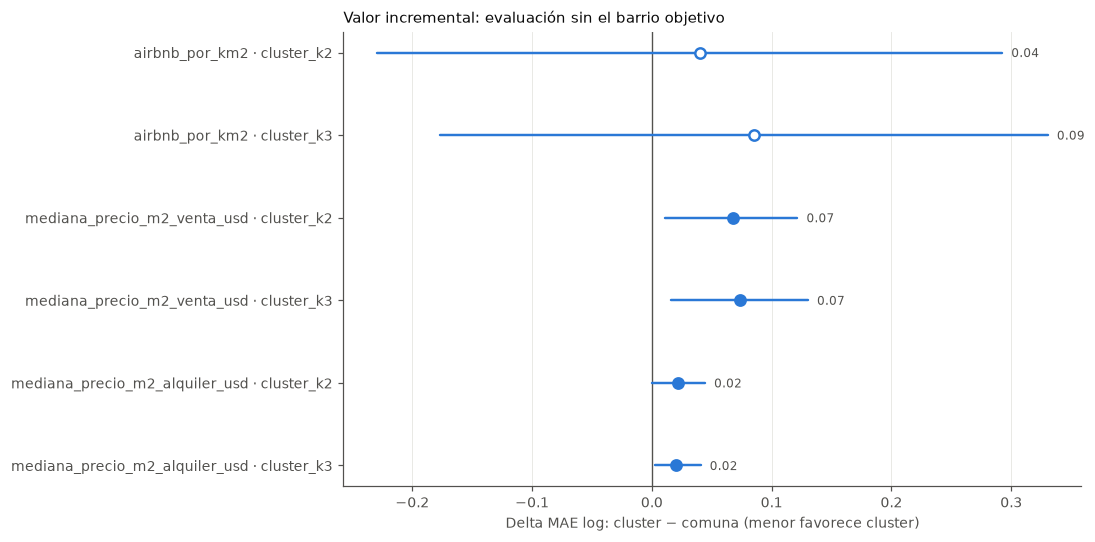

**Borrador de interpretación.** airbnb_por_km2, cluster_k2: delta MAE=+0.041, IC95% [-0.229, +0.292]. El resultado debe acompañarse de soporte/fallbacks y estabilidad; no basta con una silueta alta para recomendar grupos.

**Borrador de interpretación.** airbnb_por_km2, cluster_k3: delta MAE=+0.085, IC95% [-0.177, +0.330]. El resultado debe acompañarse de soporte/fallbacks y estabilidad; no basta con una silueta alta para recomendar grupos.

**Borrador de interpretación.** mediana_precio_m2_venta_usd, cluster_k2: delta MAE=+0.067, IC95% [+0.011, +0.121]. El resultado debe acompañarse de soporte/fallbacks y estabilidad; no basta con una silueta alta para recomendar grupos.

**Borrador de interpretación.** mediana_precio_m2_venta_usd, cluster_k3: delta MAE=+0.074, IC95% [+0.016, +0.130]. El resultado debe acompañarse de soporte/fallbacks y estabilidad; no basta con una silueta alta para recomendar grupos.

**Borrador de interpretación.** mediana_precio_m2_alquiler_usd, cluster_k2: delta MAE=+0.022, IC95% [+0.000, +0.044]. El resultado debe acompañarse de soporte/fallbacks y estabilidad; no basta con una silueta alta para recomendar grupos.

**Borrador de interpretación.** mediana_precio_m2_alquiler_usd, cluster_k3: delta MAE=+0.020, IC95% [+0.002, +0.041]. El resultado debe acompañarse de soporte/fallbacks y estabilidad; no basta con una silueta alta para recomendar grupos.

In [6]:
xz,_=R.transform_urban(urban_frame);pca=PCA().fit(xz)
n_pc=min(5,np.searchsorted(pca.explained_variance_ratio_.cumsum(),.8)+1);z=pca.transform(xz)[:,:n_pc]
sens=[]
for k in [2,3]:
    labels=KMeans(n_clusters=k,n_init=50,random_state=2026).fit_predict(z)
    sens.append(R.cluster_sensitivity(urban_frame,labels,n_pc,k))
sens=pd.concat(sens,ignore_index=True);save(sens,'clusters_sensibilidad');display(sens.round(3))
targets=kb.loc[urban_frame.index,['airbnb_por_km2','mediana_precio_m2_venta_usd','mediana_precio_m2_alquiler_usd']]
loo=R.territorial_loo(urban_frame,targets,kb.loc[urban_frame.index,'comuna'])
save(loo,'validacion_territorial_loo')
summary=loo.groupby(['objetivo','modelo']).agg(MAE_log=('error_abs','mean'),barrios=('barrio','size'),fallbacks=('fallback_global','sum')).reset_index()
save(summary,'comparacion_clusters_comunas');display(summary.round(4))
comparisons=[]
for target in targets:
    wide=loo[loo.objetivo.eq(target)].pivot(index='barrio',columns='modelo',values='error_abs')
    for k in [2,3]:
        for baseline in ['comuna','global']:
            comparisons.append(dict(objetivo=target,modelo=f'cluster_k{k}',referencia=baseline,
                                    **R.paired_error(wide[f'cluster_k{k}'],wide[baseline])))
comparisons=pd.DataFrame(comparisons);comparisons['q_BH']=R.bh(comparisons.p_wilcoxon)
save(comparisons,'valor_incremental_pareado');display(comparisons.round(4))
fig,ax=plt.subplots(figsize=(10,5));t=comparisons.query("referencia == 'comuna'").copy()
t['label']=t.objetivo+' · '+t.modelo
eda.forest(ax,t,col_etiqueta='label',col_valor='delta_mae',xlabel='Delta MAE log: cluster − comuna (menor favorece cluster)')
ax.set_title('Valor incremental: evaluación sin el barrio objetivo');figure('valor_incremental_clusters')
for _,r in t.iterrows():
    note(f"{r.objetivo}, {r.modelo}: delta MAE={r.delta_mae:+.3f}, IC95% [{r.lo:+.3f}, {r.hi:+.3f}]. "
         'El resultado debe acompañarse de soporte/fallbacks y estabilidad; no basta con una silueta alta para recomendar grupos.')

## 6. H3: diagnóstico, especificación e influencia en precios

H0 principal: coeficiente de distancia=0, bilateral; asociación porcentual exacta `100×(exp(beta)−1)` por 100 m. SE agrupados por barrio, corrección finita y referencia t con G−1 grados de libertad. No se modela venta junto con alquiler.

Diagnósticos: residuos vs ajustados, Q–Q, Breusch–Pagan y Jarque–Bera (estos dos bajo supuestos iid, solo orientativos); leverage y Cook. RESET agrupado, curvatura de distancia y controles de fuente tienen H0 explícitas y BH conjunto. Rechazar especificación implica revisar forma funcional, no descubrir mecanismos urbanos.

Sensibilidad fijada: p01–p99 de precio, quitar 1% de mayor Cook, geocodificación directa, sin Puerto Madero y fuente mayoritaria. Cambian muestra y estimando; no son réplicas independientes. Cook no justifica borrar avisos del pipeline. Los filtros de referencia se mantienen y se informa soporte. Estos modelos son explicativos; R²/AIC son ajuste interno y no precisión de un pronóstico.

Se contrastan además formas cuadrática y logarítmica de distancia sobre la misma muestra. Se compara ajuste interno y RESET agrupado y se estiman contrastes finitos de +100 m desde P25/P50/P75, con IC por covarianza agrupada. No se extrapola a distancias fuera del soporte ni se selecciona por el p más pequeño.

,operacion,escenario,n,barrios,efecto_pct,lo,hi,p,estado
0,alquiler,referencia_t_Gmenos1,8126,48,0.9710,0.3686,1.5771,0.0021,estimado
1,alquiler,precio_p01_p99,7963,48,0.9243,0.3764,1.4752,0.0014,estimado
2,alquiler,sin_1pct_Cook,8044,48,0.9562,0.3802,1.5355,0.0016,estimado
3,alquiler,geocodificacion_directa,7954,48,0.9848,0.3661,1.6073,0.0024,estimado
4,alquiler,sin_Puerto_Madero,7776,47,0.9352,0.3286,1.5455,0.0032,estimado
5,alquiler,fuente_mayoritaria,8070,48,0.9573,0.3557,1.5625,0.0024,estimado
6,venta,referencia_t_Gmenos1,36825,48,0.8374,0.0068,1.6749,0.0482,estimado
7,venta,precio_p01_p99,36087,48,0.8776,0.1052,1.6560,0.0268,estimado
8,venta,sin_1pct_Cook,36456,48,0.9398,0.1734,1.7120,0.0172,estimado
9,venta,geocodificacion_directa,35554,48,0.7863,-0.0346,1.6140,0.0601,estimado


,operacion,n,barrios,r2_ajustado,AIC,BIC,p_bp_iid,p_jb_iid,max_leverage,casos_cook_mayor_4n
0,alquiler,8126,48,0.3184,3092.2310,3477.3864,0.0,0.0,0.2001,340
1,venta,36825,48,0.4593,17152.8424,17621.1087,0.0,0.0,0.0235,1768


,operacion,test,p,H0,q_BH
0,alquiler,RESET_agrupado,0.0162,Coeficientes de predicción al cuadrado y cubo ...,0.0231
1,alquiler,curvatura_distancia,0.0072,Coeficiente cuadrático de distancia igual a cero,0.0144
2,alquiler,RESET_cuadratico,0.0158,Potencias de valores ajustados no agregan expl...,0.0231
3,alquiler,RESET_log_distancia,0.0047,Potencias de valores ajustados no agregan expl...,0.0118
4,alquiler,fuente_conjunta,0.2926,"Coeficientes de fuente iguales a cero, condici...",0.3252
5,venta,RESET_agrupado,0.0036,Coeficientes de predicción al cuadrado y cubo ...,0.0118
6,venta,curvatura_distancia,0.4134,Coeficiente cuadrático de distancia igual a cero,0.4134
7,venta,RESET_cuadratico,0.0003,Potencias de valores ajustados no agregan expl...,0.0026
8,venta,RESET_log_distancia,0.0005,Potencias de valores ajustados no agregan expl...,0.0026
9,venta,fuente_conjunta,0.2753,"Coeficientes de fuente iguales a cero, condici...",0.3252


,operacion,id_publicacion,barrio,cook,leverage
0,alquiler,MLA3786533952,Liniers,0.007877,0.016800
1,alquiler,MLA3769498452,Villa Del Parque,0.006437,0.014286
2,alquiler,MLA2063247093,Paternal,0.006428,0.091269
3,alquiler,MLA3852855200,Nueva Pompeya,0.005965,0.071936
4,alquiler,MLA2006336139,Villa Soldati,0.005667,0.200114
5,alquiler,MLA2063541623,Villa Real,0.004751,0.143318
6,alquiler,MLA3912423276,Villa Pueyrredon,0.004612,0.014139
7,alquiler,MLA3906743052,Parque Patricios,0.004356,0.029338
8,alquiler,MLA3751856736,Mataderos,0.004097,0.019699
9,alquiler,MLA3834984266,Paternal,0.003874,0.091059


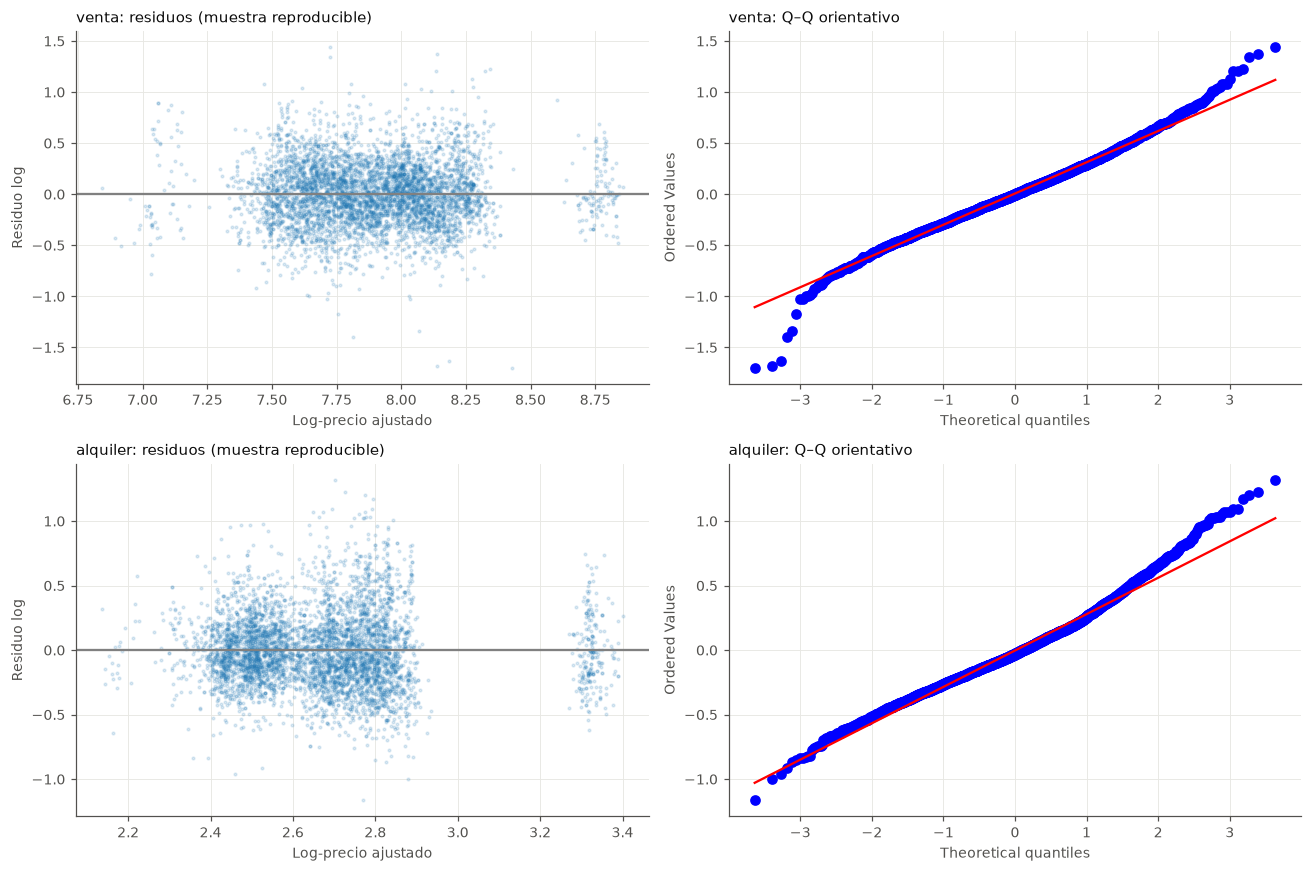

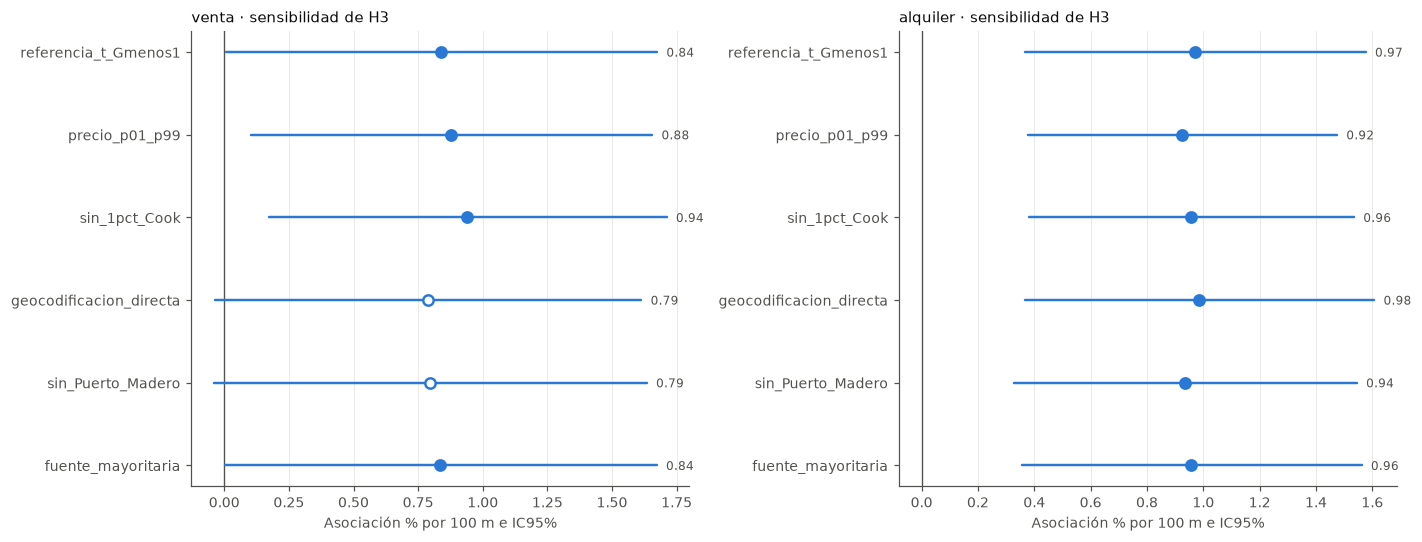

**Borrador de interpretación.** alquiler: referencia +0.97% por 100 m (IC95% [+0.37%, +1.58%]), 8,126 avisos y 48 barrios. Rango de estimaciones entre escenarios [+0.92%, +0.98%]. No permite inferir tranquilidad, ruido o preferencias; especificación, selección y geocodificación siguen condicionando la asociación.

**Borrador de interpretación.** venta: referencia +0.84% por 100 m (IC95% [+0.01%, +1.67%]), 36,825 avisos y 48 barrios. Rango de estimaciones entre escenarios [+0.79%, +0.94%]. No permite inferir tranquilidad, ruido o preferencias; especificación, selección y geocodificación siguen condicionando la asociación.

,operacion,forma,percentil_distancia,distancia_inicial_m,incremento_m,n,efecto_pct,lo,hi,r2_ajustado,AIC,RESET_p
0,alquiler,cuadratico,0.25,207.8184,100,8126,1.6005,0.7213,2.4874,0.3199,3075.2215,0.0158
1,alquiler,cuadratico,0.50,366.2638,100,8126,1.3017,0.5818,2.0268,0.3199,3075.2215,0.0158
2,alquiler,cuadratico,0.75,584.5654,100,8126,0.8915,0.3274,1.4588,0.3199,3075.2215,0.0158
3,alquiler,log_distancia,0.25,207.8184,100,8126,1.5960,0.7665,2.4325,0.3199,3074.1543,0.0047
4,alquiler,log_distancia,0.50,366.2638,100,8126,1.0997,0.5288,1.6739,0.3199,3074.1543,0.0047
5,alquiler,log_distancia,0.75,584.5654,100,8126,0.7704,0.3708,1.1717,0.3199,3074.1543,0.0047
6,venta,cuadratico,0.25,213.5075,100,36825,1.2249,0.0817,2.3811,0.4597,17123.6689,0.0003
7,venta,cuadratico,0.50,368.0547,100,36825,1.0785,0.1332,2.0328,0.4597,17123.6689,0.0003
8,venta,cuadratico,0.75,601.4668,100,36825,0.8579,-0.0059,1.7292,0.4597,17123.6689,0.0003
9,venta,log_distancia,0.25,213.5075,100,36825,1.4624,0.3226,2.6151,0.4604,17077.5244,0.0005


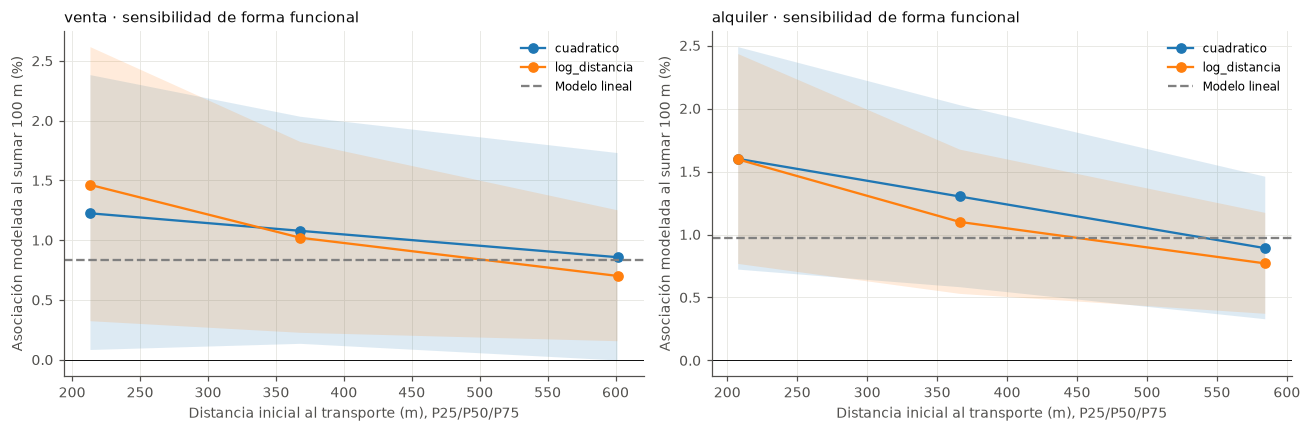

**Borrador de interpretación.** venta: RESET rechaza con q<0,05 en 3 de 3 formas evaluadas. Se conservan todas las especificaciones; no se elige por el menor p. Si persiste rechazo, la asociación lineal es una aproximación y no un efecto marginal estructural constante. Los intervalos de las curvas son puntuales con covarianza agrupada y no cubren sesgo por variables omitidas.

**Borrador de interpretación.** alquiler: RESET rechaza con q<0,05 en 3 de 3 formas evaluadas. Se conservan todas las especificaciones; no se elige por el menor p. Si persiste rechazo, la asociación lineal es una aproximación y no un efecto marginal estructural constante. Los intervalos de las curvas son puntuales con covarianza agrupada y no cubren sesgo por variables omitidas.

In [7]:
model_sens,diagnostics,influential,residuals,spec_tests,curves=model_audit(base)
save(model_sens,'h3_sensibilidad');save(diagnostics,'h3_diagnosticos');save(influential,'h3_influencia');save(spec_tests,'h3_especificacion')
display(model_sens.round(4));display(diagnostics.round(4));display(spec_tests.round(4));display(influential.head(10))
fig,axes=plt.subplots(2,2,figsize=(12,8))
for row,op in enumerate(['venta','alquiler']):
    rr=residuals[residuals.operacion.eq(op)]
    axes[row,0].scatter(rr.ajustado_log,rr.residuo_log,s=3,alpha=.15)
    axes[row,0].axhline(0,color='gray');axes[row,0].set(xlabel='Log-precio ajustado',ylabel='Residuo log',title=f'{op}: residuos (muestra reproducible)')
    stats.probplot(rr.residuo_log,dist='norm',plot=axes[row,1]);axes[row,1].set_title(f'{op}: Q–Q orientativo')
figure('h3_residuos')
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,op in zip(axes,['venta','alquiler']):
    t=model_sens[model_sens.operacion.eq(op)].dropna(subset=['efecto_pct'])
    eda.forest(ax,t,col_etiqueta='escenario',col_valor='efecto_pct',xlabel='Asociación % por 100 m e IC95%')
    ax.set_title(op+' · sensibilidad de H3')
figure('h3_forest_sensibilidad')
for op,t in model_sens.groupby('operacion'):
    ref=t[t.escenario.eq('referencia_t_Gmenos1')].iloc[0]
    note(f"{op}: referencia {ref.efecto_pct:+.2f}% por 100 m (IC95% [{ref.lo:+.2f}%, {ref.hi:+.2f}%]), "
         f"{int(ref.n):,} avisos y {int(ref.barrios)} barrios. Rango de estimaciones entre escenarios "
         f"[{t.efecto_pct.min():+.2f}%, {t.efecto_pct.max():+.2f}%]. "
         'No permite inferir tranquilidad, ruido o preferencias; especificación, selección y geocodificación siguen condicionando la asociación.')
save(curves,'h3_formas_funcionales');display(curves.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,op in zip(axes,['venta','alquiler']):
    for form,group in curves[curves.operacion.eq(op)].groupby('forma'):
        ax.plot(group.distancia_inicial_m,group.efecto_pct,marker='o',label=form)
        ax.fill_between(group.distancia_inicial_m,group.lo,group.hi,alpha=.15)
    ref=model_sens[model_sens.operacion.eq(op)&model_sens.escenario.eq('referencia_t_Gmenos1')].iloc[0]
    ax.axhline(ref.efecto_pct,ls='--',color='gray',label='Modelo lineal')
    ax.axhline(0,color='black',lw=.6)
    ax.set(xlabel='Distancia inicial al transporte (m), P25/P50/P75',ylabel='Asociación modelada al sumar 100 m (%)',title=op+' · sensibilidad de forma funcional')
    ax.legend(fontsize=8)
figure('h3_formas_funcionales')
for op in ['venta','alquiler']:
    resets=spec_tests[spec_tests.operacion.eq(op)&spec_tests.test.str.startswith('RESET')]
    note(f"{op}: RESET rechaza con q<0,05 en {int(resets.q_BH.lt(.05).sum())} de {len(resets)} formas evaluadas. "
         'Se conservan todas las especificaciones; no se elige por el menor p. '
         'Si persiste rechazo, la asociación lineal es una aproximación y no un efecto marginal estructural constante. '
         'Los intervalos de las curvas son puntuales con covarianza agrupada y no cubren sesgo por variables omitidas.')


## 7. Matriz de evidencia para el cierre posterior

Cada hallazgo debe conservar unidad, n, magnitud, incertidumbre, familia de pruebas, sensibilidad y límite. Las tablas separan p sin ajustar y q; ninguna regla obliga a obtener un resultado significativo. Los resultados negativos o inestables son parte de la entrega.

**Pendiente para el cierre conjunto:** fijar nombres sustantivos de componentes/grupos, acordar las interpretaciones finales, redactar README y narrativa ejecutiva, y completar/validar el dashboard visual. El mart no sustituye ese dashboard. No se construye un índice de necesidad si la evidencia no lo justifica.

In [8]:
matrix=evidence.merge(part[['contraste','rho','q_BH']].rename(columns={'rho':'rho_parcial','q_BH':'q_parcial'}),on='contraste')
matrix['estimador']='Spearman';matrix['estimacion']=matrix.rho
matrix['unidad_efecto']='rho';matrix['familia']='Territorial primaria, 10 contrastes'
h3_rows=model_sens[model_sens.escenario.eq('referencia_t_Gmenos1')].copy()
h3_rows['q_H3']=R.bh(h3_rows.p)
new=[]
for _,r in h3_rows.iterrows():
    new.append(dict(contraste='H3_'+r.operacion,hipotesis='H3',unidad='publicación; SE agrupados por barrio',n=r.n,
                    estimador='OLS log-lineal, t con G−1',estimacion=r.efecto_pct,lo=r.lo,hi=r.hi,
                    unidad_efecto='% por 100 m',p_perm=np.nan,q_BH=r.q_H3,p_modelo=r.p,
                    familia='H3 primaria, 2 operaciones',barrios=r.barrios))
matrix=pd.concat([matrix,pd.DataFrame(new)],ignore_index=True)
matrix['limite']='Corte transversal; cobertura por fuente; dependencia territorial; proxy y unidad específicos'
matrix['estado']='Interpretación provisional; revisar junto a sensibilidades'
save(matrix,'matriz_evidencia');display(matrix[['contraste','n','estimador','estimacion','unidad_efecto','lo','hi','q_BH','rho_parcial','q_parcial']].round(4))
note('La validación técnica confirma ejecución; la validez sustantiva depende de supuestos, tamaño y estabilidad. '
     'La entrega debe comunicar asociaciones robustas y también dónde los datos no discriminan decisiones. '
     'Los archivos v2 conservan cada contraste y escenario para revisión, sin reemplazar datos crudos ni el README.')

,contraste,n,estimador,estimacion,unidad_efecto,lo,hi,q_BH,rho_parcial,q_parcial
0,H1_cultura,48,Spearman,0.8548,rho,0.7133,0.9197,0.0017,0.6313,0.0050
1,H1_gastronomia,48,Spearman,0.6464,rho,0.3888,0.8123,0.0017,0.3545,0.0340
2,H2a_venta,15,Spearman,-0.2857,rho,-0.7190,0.3622,0.3869,-0.3614,0.3321
3,H2a_alquiler,15,Spearman,0.0286,rho,-0.6107,0.7327,0.9295,0.2139,0.5306
4,H2a_alquiler_temporal,15,Spearman,-0.5000,rho,-0.8629,0.0783,0.1158,-0.2956,0.4100
5,H2b_culturales,15,Spearman,0.6857,rho,0.1875,0.9230,0.0160,0.8003,0.0087
6,H2b_educacion,15,Spearman,0.1107,rho,-0.5820,0.7071,0.7700,-0.0945,0.7500
7,H2b_espacios_verdes,15,Spearman,0.4107,rho,-0.2669,0.7719,0.1857,0.4296,0.2317
8,H4_precio,15,Spearman,0.9071,rho,0.6217,0.9854,0.0017,0.9081,0.0050
9,H4_disponibilidad,15,Spearman,0.8321,rho,0.5072,0.9706,0.0025,0.8275,0.0050


**Borrador de interpretación.** La validación técnica confirma ejecución; la validez sustantiva depende de supuestos, tamaño y estabilidad. La entrega debe comunicar asociaciones robustas y también dónde los datos no discriminan decisiones. Los archivos v2 conservan cada contraste y escenario para revisión, sin reemplazar datos crudos ni el README.